# Diverging Bar Chart

**Family:** Deviation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Deviation:* Emphasise variations (+/-) from a fixed reference point: zero, a target, or an average.

## Design purpose

A bar chart whose bars grow left or right (or up or down) from a shared reference line. Color shows direction, so the eye picks out above and below the baseline before reading magnitude.

## When to use

- Show how far each category sits above or below a baseline (zero, target, average)
- Show signed values such as profit/loss, budget variance, or year-over-year change
- Rank items by deviation while keeping the sign visible

## Avoid when

- There is no meaningful reference point (use a plain bar chart)
- Values are all positive and the baseline is arbitrary
- There are more than ~30 categories (consider a dot plot or table)

## Alternatives

- Deviation lollipop
- Surplus/deficit line (for time series)

## Design tips

- Sort bars by value so the zero-crossing is easy to locate
- Use two opposite hues (warm/cool), never two shades of the same hue
- Put category labels next to the bar's base, not inside the bars

## Example

Change in annual sales versus the previous year for 12 product lines.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(7)
products = [f"Product {c}" for c in "ABCDEFGHIJKL"]
df = pd.DataFrame({"product": products,
                   "yoy_change_pct": rng.normal(2, 9, len(products)).round(1)})
df = df.sort_values("yoy_change_pct")
df.head()

,product,yoy_change_pct
5,Product F,-6.9
3,Product D,-6.0
9,Product J,-3.6
8,Product I,-2.4
4,Product E,-2.1


### Plot

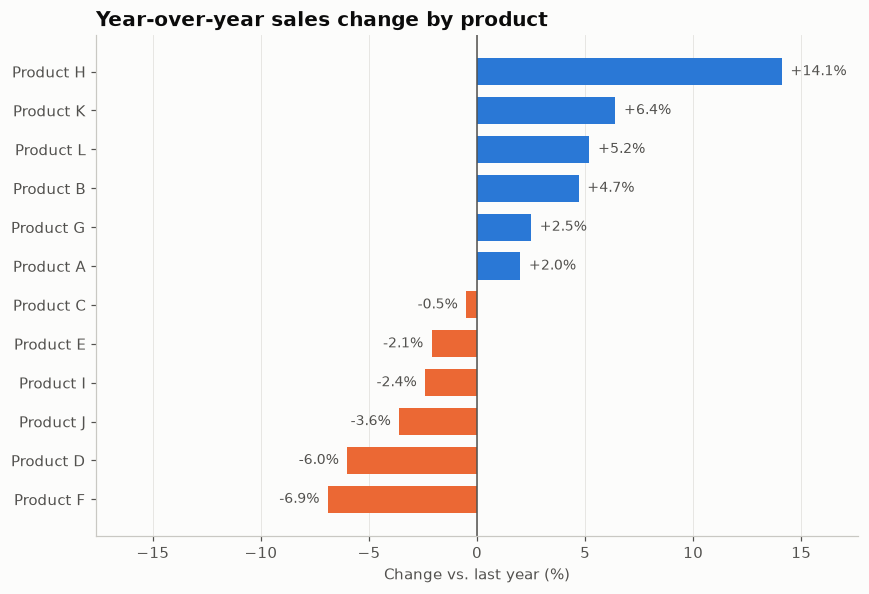

In [3]:
colors = np.where(df["yoy_change_pct"] >= 0, PALETTE[0], PALETTE[1])
fig, ax = plt.subplots(figsize=(8, 5.5))
ax.barh(df["product"], df["yoy_change_pct"], color=colors, height=0.7)
ax.axvline(0, color="#52514e", linewidth=1)
for y, v in enumerate(df["yoy_change_pct"]):
    ax.text(v + (0.4 if v >= 0 else -0.4), y, f"{v:+.1f}%", va="center",
            ha="left" if v >= 0 else "right", fontsize=9, color="#52514e")
ax.set_xlabel("Change vs. last year (%)")
ax.set_title("Year-over-year sales change by product")
ax.grid(axis="y", visible=False)
lim = df["yoy_change_pct"].abs().max() * 1.25
ax.set_xlim(-lim, lim)
fig.tight_layout()
plt.show()

## How to read it

Bars to the right of zero (blue) grew and bars to the left (orange) shrank. Bar length is the size of the change.

---
Standalone script: [`diverging_bar.py`](diverging_bar.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)